In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load and Excel Sheets as DFs:

In [2]:
CO2_df = pd.read_excel("Emissions2024.xlsx", sheet_name='CO2', header=1, skipfooter=2).query("`Plant Code`!=99999")
SO2_df = pd.read_excel("Emissions2024.xlsx", sheet_name='SO2', header=1, skipfooter=2).query("`Plant Code`!=99999")
NOx_df = pd.read_excel("Emissions2024.xlsx", sheet_name='NOx', header=1, skipfooter=2).query("`Plant Code`!=99999")

# Cast SO2 and NOx Emissions as a Float:

In [3]:
SO2_df['EIA Model Estimates of SO2 Emissions (Tons)'] = SO2_df['EIA Model Estimates of SO2 Emissions (Tons)'].replace(' ', 0)
SO2_df['EIA Model Estimates of SO2 Emissions (Tons)'] = SO2_df['EIA Model Estimates of SO2 Emissions (Tons)'].astype('float')
NOx_df['EIA Model Estimates of NOx Emissions (Tons)'] = NOx_df['EIA Model Estimates of NOx Emissions (Tons)'].replace(' ', 0)
NOx_df['EIA Model Estimates of NOx Emissions (Tons)'] = NOx_df['EIA Model Estimates of NOx Emissions (Tons)'].astype('float')

# Impute values for Alaska/Hawaii in NERC and balancing authority UNFINSIHED

In [4]:
CO2_df['NERC Region'].value_counts()

NERC Region
SERC    1109
RFC      922
WECC     887
MRO      880
NPCC     584
TRE      400
Name: count, dtype: int64

# Translate Prime Mover and Fuel Codes to their actual values:

In [5]:
pm_replace_map = {'IC': 'Internal Combustion Engine',
'CA': 'Combined Cycle Steam Part',
'CT': 'Combined Cycle Combustion Turbine Part',
'ST': 'Steam Turbine',
'GT': 'Combustion (Gas) Turbine',
'CS': 'Combined Cycle Single Shaft',
'CE': 'Energy Storage, Compressed Air',
'OT': 'Other',
'FC': 'Fuel Cell'
}
 
CO2_df['Prime Mover'] = CO2_df['Prime Mover'].replace(pm_replace_map)
SO2_df['Prime Mover'] = SO2_df['Prime Mover'].replace(pm_replace_map)
NOx_df['Prime Mover'] = NOx_df['Prime Mover'].replace(pm_replace_map)

In [6]:
fuel_replace_map = {
    'ANT': 'Anthracite Coal',
    'BIT': 'Bituminous Coal',
    'LIG': 'Lignite Coal',
    'SGC': 'Coal-Derived Synthesis Gas',
    'SUB': 'Subbituminous Coal',
    'WC':  'Waste/Other Coal',
    'RC':  'Refined Coal',
    'DFO': 'Distillate Fuel Oil',
    'JF':  'Jet Fuel',
    'KER': 'Kerosene',
    'PC':  'Petroleum Coke',
    'PG':  'Gaseous Propane',
    'RFO': 'Residual Fuel Oil',
    'SGP': 'Synthesis Gas from Petroleum Coke',
    'WO':  'Waste/Other Oil',
    'BFG': 'Blast Furnace Gas',
    'NG':  'Natural Gas',
    'H2':  'Hydrogen',
    'OG':  'Other Gas',
    'AB':  'Agricultural By-Products',
    'MSW': 'Municipal Solid Waste',
    'OBS': 'Other Biomass Solids',
    'WDS': 'Wood/Wood Waste Solids',
    'OBL': 'Other Biomass Liquids',
    'SLW': 'Sludge Waste',
    'BLQ': 'Black Liquor',
    'WDL': 'Wood Waste Liquids excluding Black Liquor',
    'LFG': 'Landfill Gas',
    'OBG': 'Other Biomass Gas',
    'SUN': 'Solar',
    'WND': 'Wind',
    'GEO': 'Geothermal',
    'WAT': 'Water'
}
 
CO2_df['Fuel Code'] = CO2_df['Fuel Code'].replace(fuel_replace_map)
SO2_df['Fuel Code'] = SO2_df['Fuel Code'].replace(fuel_replace_map)
NOx_df['Fuel Code'] = NOx_df['Fuel Code'].replace(fuel_replace_map)

# Create a unique key column for each DF:

In [7]:
CO2_df['Plant Code'] = CO2_df['Plant Code'].astype('str')
CO2_df['Sector Code'] = CO2_df['Sector Code'].astype('str')
CO2_df['Plant_PM_Fuel'] = CO2_df['Plant Code'] + '_' + CO2_df['Sector Code'] + '_' + CO2_df['Prime Mover'] + '_' + CO2_df['Fuel Code']

In [8]:
SO2_df['Plant Code'] = SO2_df['Plant Code'].astype('str')
SO2_df['Sector Code'] = SO2_df['Sector Code'].astype('str')
SO2_df['Plant_PM_Fuel'] = SO2_df['Plant Code'] + '_' + SO2_df['Sector Code'] + '_' + SO2_df['Prime Mover'] + '_' + SO2_df['Fuel Code']

In [9]:
NOx_df['Plant Code'] = NOx_df['Plant Code'].astype('str')
NOx_df['Sector Code'] = NOx_df['Sector Code'].astype('str')
NOx_df['Plant_PM_Fuel'] = NOx_df['Plant Code'] + '_' + NOx_df['Sector Code'] + '_' + NOx_df['Prime Mover'] + '_' + NOx_df['Fuel Code']

In [10]:
SO2_df.columns

Index(['Plant Code', 'Plant Name', 'State', 'Sector Group', 'Sector Code',
       'Prime Mover', 'Fuel Code', 'Aggregated Fuel Group', 'Generation (kWh)',
       'Useful Thermal Output (MMBtu)', 'Total Fuel Consumption (MMBtu)',
       'Fuel Consumption for Electric Generation (MMBtu)',
       '\n Fuel Consumption for Useful Thermal Output (MMBtu)',
       'Quantity of Fuel Consumed', 'Fuel Units',
       'Sulfur Content of Fuel Used in EIA Model (%)',
       'EIA Model Estimates of SO2 Emissions (Tons)',
       'EIA Model Estimates of Plant Level SO2 Emissions (Tons)',
       'CEMS Reported Plant Level SO2 Emissions (Tons)',
       'Selected SO2 Emissions (Tons)',
       'Selected SO2 Emissions (Metric Tonnes)', 'NERC Region',
       'Balancing Authority Code', 'Balancing Authority Name',
       'EIA Balancing Authority Region', 'Plant_PM_Fuel'],
      dtype='str')

# Inner Merge Emissions Outputs into one DF:

In [11]:
CO2_SO2 = pd.merge(
    CO2_df, 
    SO2_df[['Plant_PM_Fuel', 'EIA Model Estimates of SO2 Emissions (Tons)', 'Selected SO2 Emissions (Tons)']], 
    on='Plant_PM_Fuel', 
    how='inner',
    validate = 'one_to_one',
    indicator='matched'
)

In [12]:
CO2_SO2.query("matched != 'both'").T

""
Plant Code
Plant Name
State
Sector Group
Sector Code
Prime Mover
Fuel Code
Aggregated Fuel Group
Generation (kWh)
Useful Thermal Output (MMBtu)


In [13]:
tp = pd.merge(
    CO2_SO2, 
    NOx_df[['Plant_PM_Fuel', 'EIA Model Estimates of NOx Emissions (Tons)', 'Selected NOx Emissions (Tons)']], 
    on='Plant_PM_Fuel', 
    how='inner'
)

# Remove irrelevant columns in total pollution df:

In [14]:
nan_cols = tp.columns[tp.isna().any()].tolist()
print(nan_cols)

['NERC Region', 'Balancing Authority Code']


In [15]:
tp.columns

Index(['Plant Code', 'Plant Name', 'State', 'Sector Group', 'Sector Code',
       'Prime Mover', 'Fuel Code', 'Aggregated Fuel Group', 'Generation (kWh)',
       'Useful Thermal Output (MMBtu)', 'Total Fuel Consumption (MMBtu)',
       'Fuel Consumption for Electric Generation (MMBtu)',
       '\n Fuel Consumption for Useful Thermal Output (MMBtu)',
       'Quantity of Fuel Consumed', 'Fuel Units', 'Tons of CO2 Emissions',
       'Metric Tonnes of CO2 Emissions', 'NERC Region',
       'Balancing Authority Code', 'Balancing Authority Name',
       'EIA Balancing Authority Region', 'Plant_PM_Fuel',
       'EIA Model Estimates of SO2 Emissions (Tons)',
       'Selected SO2 Emissions (Tons)', 'matched',
       'EIA Model Estimates of NOx Emissions (Tons)',
       'Selected NOx Emissions (Tons)'],
      dtype='str')

In [16]:
clean_cols = ['Plant_PM_Fuel', 'Plant Code', 'Plant Name', 'State', 'Sector Group', 'Sector Code',
       'Prime Mover', 'Fuel Code', 'Aggregated Fuel Group', 'Generation (kWh)',
       'Fuel Consumption for Electric Generation (MMBtu)',
       'NERC Region',
       'Balancing Authority Code', 'Balancing Authority Name',
       'EIA Balancing Authority Region',
       'Tons of CO2 Emissions',
       'Selected SO2 Emissions (Tons)',
       'Selected NOx Emissions (Tons)']

In [17]:
tp_clean = tp[clean_cols]
tp_clean.head(3).T

,0,1,2
Plant_PM_Fuel,1_1_Internal Combustion Engine_Distillate Fuel...,3_1_Combined Cycle Steam Part_Natural Gas,3_1_Combined Cycle Combustion Turbine Part_Nat...
Plant Code,1,3,3
Plant Name,Sand Point,Barry,Barry
State,AK,AL,AL
Sector Group,ELECTRIC POWER,ELECTRIC POWER,ELECTRIC POWER
Sector Code,1,1,1
Prime Mover,Internal Combustion Engine,Combined Cycle Steam Part,Combined Cycle Combustion Turbine Part
Fuel Code,Distillate Fuel Oil,Natural Gas,Natural Gas
Aggregated Fuel Group,PET,GAS,GAS
Generation (kWh),3616000,4519611000,8653458000


# Rolling up the data to the plant level:

In [18]:
def rollup_eia_emissions_to_plant(df: pd.DataFrame) -> pd.DataFrame:
  """
    Rolls up a merged EIA 2024 emissions DataFrame (CO2, SO2, NOx) to one row per Plant Code.
    Prevents double-counting of repeated plant-level CEMS/Model columns and avoids summing
    physical fuel quantities with incompatible units.
    """
  df = df.copy()
  df.columns = df.columns.str.strip()

  # 1. Clean numeric columns (EIA often uses blank strings " " or commas in numeric fields)
  plant_level_cols = [
      'EIA Model Estimates of Plant Level SO2 Emissions (Tons)',
      'CEMS Reported Plant Level SO2 Emissions (Tons)',
      'EIA Model Estimates of Plant Level NOx Emissions (Tons)',
      'CEMS Reported Plant Level NOx Emissions (Tons)',
  ]

  row_sum_cols = [
      'Generation (kWh)',
      'Useful Thermal Output (MMBtu)',
      'Total Fuel Consumption (MMBtu)',
      'Fuel Consumption for Electric Generation (MMBtu)',
      'Fuel Consumption for Useful Thermal Output (MMBtu)',
      'Tons of CO2 Emissions',
      'Metric Tonnes of CO2 Emissions',
      'EIA Model Estimates of SO2 Emissions (Tons)',
      'Selected SO2 Emissions (Tons)',
      'Selected SO2 Emissions (Metric Tonnes)',
      'EIA Model Estimates of NOx Emissions (Tons)',
      'Selected NOx Emissions (Tons)',
      'Selected NOx Emissions (Metric Tonnes)',
  ]

  numeric_cols = [
      c for c in (plant_level_cols + row_sum_cols) if c in df.columns
  ]
  for col in numeric_cols:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(',', '').str.strip(), errors='coerce'
    )

  # 2. Define aggregation dictionary dynamically based on columns present in your merged table
  agg_rules = {}

  # Text/metadata columns: take the first non-null value per plant
  metadata_cols = [
      'Plant Name',
      'State',
      'Sector Group',
      'Sector Code',
      'NERC Region',
      'Balancing Authority Code',
      'Balancing Authority Name',
      'EIA Balancing Authority Region',
  ]
  for col in metadata_cols:
    if col in df.columns:
      agg_rules[col] = 'first'

  # Unit-level operational & emission columns: safe to SUM across prime movers/fuels
  for col in row_sum_cols:
    if col in df.columns:
      agg_rules[col] = lambda s: s.sum(min_count=1)  # Keeps NaN if all rows are NaN

  # Plant-level repeated columns: take MAX (or FIRST) so they are NOT summed
  for col in plant_level_cols:
    if col in df.columns:
      agg_rules[col] = 'max'

  # Categorical descriptors: combine unique values into a comma-separated list for reference
  for col in ['Prime Mover', 'Fuel Code', 'Aggregated Fuel Group']:
    if col in df.columns:
      agg_rules[col] = lambda s: ', '.join(
          sorted(s.dropna().astype(str).unique())
      )

  # Note: 'Quantity of Fuel Consumed', 'Fuel Units', and 'Sulfur Content (%)' are intentionally
  # excluded because physical units (Tons, Mcf, Barrels) cannot be summed across different fuels.

  # 3. Group by Plant Code (excluding the 99999 state-level "Estimate for Missing Data" placeholder)
  df_plants = df[df['Plant Code'] != 99999].groupby('Plant Code', as_index=False).agg(agg_rules)

  # Optional: Keep 99999 ("Estimate for Missing Data") grouped by Plant Code + State so states don't merge
  if 99999 in df['Plant Code'].values:
    df_missing = (
        df[df['Plant Code'] == 99999]
        .groupby(['Plant Code', 'State'], as_index=False)
        .agg(agg_rules)
    )
    df_plants = pd.concat([df_plants, df_missing], ignore_index=True)

  return df_plants


# Example usage:
# plant_df = rollup_eia_emissions_to_plant(merged_df)


In [19]:
tp_plant = rollup_eia_emissions_to_plant(tp_clean)

In [20]:
tp_plant = tp_plant.drop('Balancing Authority Name', axis = 1)

# Fill NA values in NERC and Balancing Authority Code with values from Balancing Authority region

In [21]:
tp_plant['Balancing Authority Code'] = tp_plant['Balancing Authority Code'].fillna(tp_plant['EIA Balancing Authority Region'])
tp_plant['NERC Region'] = tp_plant['NERC Region'].fillna(tp_plant['EIA Balancing Authority Region'])

# Cast columns appropriately and reorder:

In [22]:
tp_plant = tp_plant.astype({"Plant Code": "category", 
                            "Plant Name": "category", 
                            "State": "category", 
                            "Sector Group": "category",
                            "Sector Code": "category",
                            "Prime Mover": "category",
                            "Fuel Code": "category",
                            "Aggregated Fuel Group": "category",
                            "Generation (kWh)": "float64",
                            "Fuel Consumption for Electric Generation (MMBtu)": "float64",
                            "NERC Region": "category",
                            "Balancing Authority Code": "category",
                            "EIA Balancing Authority Region": "category",
                            "Tons of CO2 Emissions": "float64",
                            "Selected SO2 Emissions (Tons)": "float64",
                            "Selected NOx Emissions (Tons)": "float64",
                            })


In [ ]:
tp_plant = tp_plant[['Plant Code', 'Plant Name', 
                     'Aggregated Fuel Group', 'Fuel Code', 'Fuel Consumption for Electric Generation (MMBtu)', 'Prime Mover',
                     'Tons of CO2 Emissions', 'Selected SO2 Emissions (Tons)', 'Selected NOx Emissions (Tons)', 'Generation (kWh)', 
                     'State', 'NERC Region', 'Balancing Authority Code', 'EIA Balancing Authority Region', 'Sector Code', 'Sector Group']]

In [39]:
tp_plant.head()

,Plant Code,Plant Name,Aggregated Fuel Group,Fuel Code,Fuel Consumption for Electric Generation (MMBtu),Prime Mover,Tons of CO2 Emissions,Selected SO2 Emissions (Tons),Selected NOx Emissions (Tons),Generation (mWh),State,NERC Region,Balancing Authority Code,EIA Balancing Authority Region,Sector Code,Sector Group
0,1,Sand Point,PET,Distillate Fuel Oil,39104.0,Internal Combustion Engine,3196.0,5.0,59.0,3616.000,AK,Alaska,Alaska,Alaska,1,ELECTRIC POWER
1,10,Greene County,"GAS, PET","Distillate Fuel Oil, Natural Gas",16152399.0,"Combustion (Gas) Turbine, Steam Turbine",942668.0,5.0,1171.0,1489027.000,AL,SERC,SOCO,Southeast,1,ELECTRIC POWER
2,10003,Colorado Energy Nations Company,GAS,Natural Gas,840377.0,Steam Turbine,235566.0,1.0,228.0,144278.355,CO,WECC,PSCO,Northwest,7,INDUSTRIAL
3,10008,Baptist Medical Center,GAS,Natural Gas,115661.0,Combustion (Gas) Turbine,17298.0,0.0,47.0,19932.220,FL,SERC,JEA,Florida,5,COMMERCIAL
4,10013,Covanta Hennepin Energy,"GAS, MSW","Municipal Solid Waste, Natural Gas",3844746.0,Steam Turbine,211500.0,310.0,352.0,205597.000,MN,MRO,MISO,Midwest,2,ELECTRIC POWER


ValueError: Could not interpret value `Generation (kWh)` for `y`. An entry with this name does not appear in `data`.

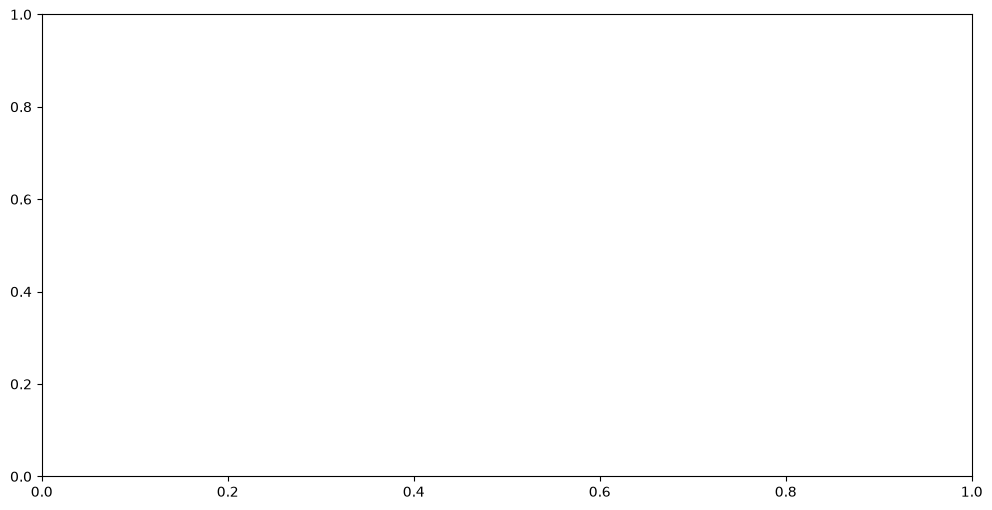

In [41]:
fig, ax = plt.subplots(figsize=(12, 6))

sns.scatterplot(data=tp_plant, x="Fuel Consumption for Electric Generation (MMBtu)", y="Generation (kWh)", hue = 'Aggregated Fuel Group')

plt.title("Electric Fuel Consumption vs. Total NOx Emissions (Tons)")
plt.show()